# 04 · Does the membrane mind the sun?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EngMtaleb/chemai/blob/main/projects/p04_tide_fouling/notebooks/04_the_sun_tests.ipynb)

A plant that runs on solar power makes its water in daylight and stops at night. That could cost
the pre-treatment membrane in two ways: the **daylight hours** might foul faster (warmer water, sun
on the intake, the sea's own daily rhythm), and the **morning restart** might foul faster (a
membrane that stood still overnight). Both were declared before they were tested
(`DECLARED_BEFORE_RUN_2.md`, commit `6d3dd6e`):

> - **H2 — the sun's clock.** Harmonics of the day (24, 12, 8, 6 h); null: each shift block's clock
>   moved by an independent uniform 1–23 h, which scrambles the time of day and nothing else.
>   Decision number: the fitted daily profile's mean over 09:00–15:00 minus the other 18 hours, as a
>   share of the median. Positive control: the water temperature must follow the hour.
> - **H3 — the morning restart.** In the first 3 h after the unit stood idle at least 2 h, against
>   the rest of its first 12 h; cluster-robust by episode. Placebo: a pretend restart 24 h in.

**Data:** a public seawater ultrafiltration (UF) pilot record, pre-treatment for a reverse-osmosis pilot, 2012–2015: Zenodo [4630769](https://zenodo.org/records/4630769), also Dryad [doi:10.5068/D1310B](https://doi.org/10.5068/D1310B), CC0. The site is not named here. The notebooks read the tables committed in `results/`; the 356 MB raw archive is needed only where a cell says so.

Script version: `step5_sun_power.py`, `step6_sun_tests.py` · record: `VALIDATION.md`, section 7.

In [1]:
# Setup. In Google Colab this clones the repository and installs the package (about a minute).
# On your own machine, run from a clone after:  pip install -e ".[viz,data]"
import os, subprocess, sys
from pathlib import Path
REF = "main"        # before the Project 4 pull request is merged, use "p04-tide-fouling"
if "google.colab" in sys.modules:
    if not Path("/content/chemai").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", "--branch", REF,
                        "https://github.com/EngMtaleb/chemai.git", "/content/chemai"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "/content/chemai[viz,data]"], check=True)
    sys.path.insert(0, "/content/chemai")
    ROOT = Path("/content/chemai")
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
P4 = ROOT / "projects" / "p04_tide_fouling"
RES = P4 / "results"

import json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)
INK, MUTED, BLUE, ORANGE, GREEN, RED, SUN = "#1f2933", "#7b8794", "#2f6fb2", "#d9822b", "#3f8f5a", "#c23b3b", "#f2c14e"

def load(name):
    """A committed result file from projects/p04_tide_fouling/results/."""
    return json.loads((RES / name).read_text())

In [2]:
from chemai.evaluation.tide_test import (DAY_HARMONICS, PLACEBO, TideTestConfig, confirm_out_of_sample,
                                         harmonic_block, prepare, tide_design, tide_test)
from chemai.evaluation.restart_test import RestartConfig, restart_test, window
seg = pd.read_parquet(RES / "segments.parquet")
ep = pd.read_parquet(RES / "episodes.parquet")
cfg, rcfg = TideTestConfig(), RestartConfig()
BASE = dict(tod=False, temperature=False)      # the hour is what is tested; viscosity is already inside R
prep = prepare(seg, "fouling_pct_h", cfg, **BASE)
med = float(np.median(prep.y))
print(f"{len(prep.y):,} segments, median fouling rate {med:.2f} %/h")

14,998 segments, median fouling rate 13.17 %/h


## 1. H2: does the fouling rate follow the hour?

First the positive control, because a clock test is only worth something if it can see a clock.
Water temperature follows the sun:

In [3]:
c3 = tide_test(prepare(seg, "temp_c", cfg, **BASE), DAY_HARMONICS, cfg, "temp_c", shift="hours")
h2 = tide_test(prep, DAY_HARMONICS, cfg, "fouling_pct_h", shift="hours")
plac = tide_test(prep, PLACEBO, cfg, "fouling_pct_h", shift="hours", with_ranges=False)
split = pd.Timestamp("2014-01-01")
conf = confirm_out_of_sample(prepare(seg[seg.t_std < split], "fouling_pct_h", cfg, **BASE),
                             prepare(seg[seg.t_std >= split], "fouling_pct_h", cfg, **BASE),
                             DAY_HARMONICS, cfg, shift="hours")
pd.DataFrame([
    ("water temperature (positive control C3)", c3.p_value, f"explains {c3.partial_r2:.0%} of what is left"),
    ("fouling rate (H2)", h2.p_value, f"explains {h2.partial_r2:.3%} (chance: up to {h2.null_partial_r2_q95:.3%})"),
    ("fouling rate, placebo periods", plac.p_value, "quiet, as it should be"),
    ("fitted before 2014, scored after", conf["p_value"], f"explains {conf['oos_variance_share']:+.2%}"),
], columns=["test", "p", "note"]).round(3)

,test,p,note
0,water temperature (positive control C3),0.001,explains 44% of what is left
1,fouling rate (H2),0.746,explains 0.028% (chance: up to 0.092%)
2,"fouling rate, placebo periods",0.330,"quiet, as it should be"
3,"fitted before 2014, scored after",0.897,explains -0.27%


The test sees the temperature's daily cycle at once (p = 0.001, the smallest possible with 999
surrogates). It sees nothing in the fouling rate: **p = 0.746**.

How big a daily effect could still hide? The decision number, with a bootstrap over shift blocks
(the same 999 resamples as `step6_sun_tests.py`):

09-15 h against the rest: -0.8% of the median rate (95 % interval -2.5% to +1.2%)


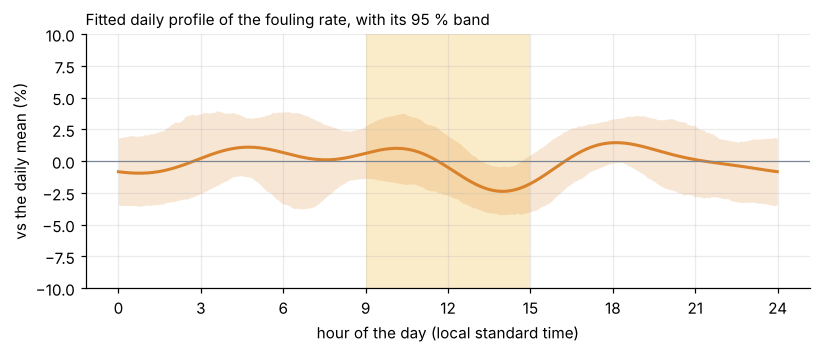

In [4]:
tau = np.arange(0, 24, 1 / 60)
xt, _ = harmonic_block(tau, DAY_HARMONICS)
sun_hours = (tau >= 9) & (tau < 15)
contrast = lambda beta: float((xt @ beta)[sun_hours].mean() - (xt @ beta)[~sun_hours].mean())

d = tide_design(prep, DAY_HARMONICS)
t_res = d.zcat.reshape(len(prep.y), len(d.blocks), d.width).sum(axis=1)     # the real clock
idx = {b: np.flatnonzero(prep.block == b) for b in d.blocks}
rng = np.random.default_rng(7)
boot_beta = []
for _ in range(999):
    rows = np.concatenate([idx[b] for b in rng.choice(d.blocks, len(d.blocks), replace=True)])
    boot_beta.append(np.linalg.lstsq(t_res[rows], prep.y_res[rows], rcond=None)[0])
boot_beta = np.array(boot_beta)
ci = np.quantile([contrast(b) for b in boot_beta], [0.025, 0.975]) / med
print(f"09-15 h against the rest: {contrast(np.array(h2.beta)) / med:+.1%} of the median rate "
      f"(95 % interval {ci[0]:+.1%} to {ci[1]:+.1%})")

prof = xt @ np.array(h2.beta) / med * 100
band = np.quantile(boot_beta @ xt.T, [0.025, 0.975], axis=0) / med * 100
fig, ax = plt.subplots(figsize=(8.5, 3))
ax.axvspan(9, 15, color=SUN, alpha=0.3, lw=0, label="09-15 h")
ax.fill_between(tau, band[0], band[1], color=ORANGE, alpha=0.2, lw=0)
ax.plot(tau, prof, color=ORANGE, lw=2)
ax.axhline(0, color=MUTED, lw=0.8); ax.set_ylim(-10, 10); ax.set_xticks(range(0, 25, 3))
ax.set_xlabel("hour of the day (local standard time)"); ax.set_ylabel("vs the daily mean (%)")
ax.set_title("Fitted daily profile of the fouling rate, with its 95 % band", loc="left", fontsize=10)
plt.show()

**The daylight hours foul like the rest of the day: −0.8 % (−2.6 % to +1.2 %).** The declared
relevance line was 10 %; the whole interval sits inside ±3 %. A daily wave of 10 % of the median
would have been found 99.5 % of the time (`step5_sun_power.json`).

## 2. H3: does the morning restart cost anything?

In [5]:
s = seg.merge(ep, on="episode", how="left")
w = window(s[s.idle_before_h >= rcfg.min_gap_hours], "episode_start", rcfg)
h3 = restart_test(w, cfg=rcfg)
span = (s.groupby("episode").t_start.max() - s.groupby("episode").episode_start.first()).dt.total_seconds() / 3600
long_eps = span[span >= rcfg.placebo_start_hours + rcfg.window_hours].index
pl = restart_test(window(s[s.episode.isin(long_eps)], "episode_start", rcfg, offset_h=rcfg.placebo_start_hours), cfg=rcfg)
parts = {"all restarts (H3)": h3, "pretend restart 24 h in (placebo)": pl,
         "2012-2013": restart_test(w[w.episode_start < split], cfg=rcfg),
         "2014-2015": restart_test(w[w.episode_start >= split], cfg=rcfg),
         "idle 2-12 h (exploratory)": restart_test(w[w.idle_before_h < 12], cfg=rcfg),
         "idle over 12 h (exploratory)": restart_test(w[w.idle_before_h >= 12], cfg=rcfg)}
pd.DataFrame({k: {"restarts": r.n_episodes, "segments": r.n_segments,
                  "first 3 h vs rest of first 12 h": f"{r.relative_effect:+.1%}",
                  "95 % interval": f"{r.ci95[0] / r.median_y:+.1%} to {r.ci95[1] / r.median_y:+.1%}",
                  "p": round(r.p_value, 3)} for k, r in parts.items()}).T

,restarts,segments,first 3 h vs rest of first 12 h,95 % interval,p
all restarts (H3),81,2503,+3.1%,-3.9% to +10.0%,0.382
pretend restart 24 h in (placebo),40,1493,-1.3%,-14.2% to +11.6%,0.842
2012-2013,39,892,+2.3%,-11.7% to +16.4%,0.74
2014-2015,42,1611,+1.9%,-8.5% to +12.2%,0.718
idle 2-12 h (exploratory),16,501,+12.9%,-17.8% to +43.6%,0.383
idle over 12 h (exploratory),65,2002,+2.9%,-4.2% to +9.9%,0.42


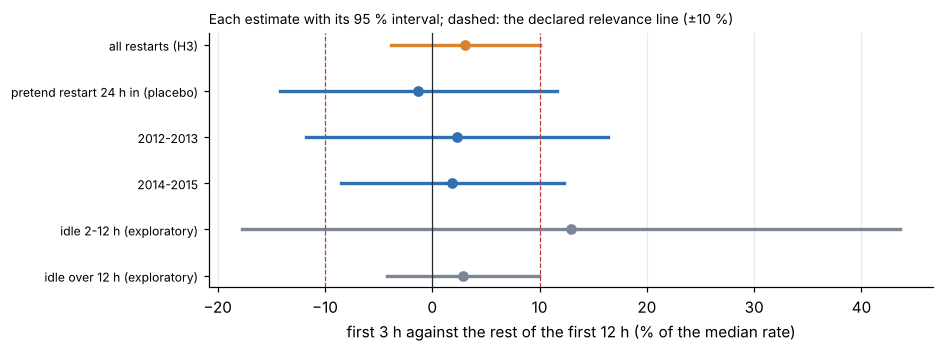

In [6]:
labels = list(parts)[::-1]
fig, ax = plt.subplots(figsize=(8.5, 3))
for i, k in enumerate(labels):
    r = parts[k]
    lo, hi = np.array(r.ci95) / r.median_y * 100
    c = ORANGE if k.startswith("all") else (MUTED if "exploratory" in k else BLUE)
    ax.plot([lo, hi], [i, i], color=c, lw=2.2)
    ax.plot(r.relative_effect * 100, i, "o", color=c)
ax.axvline(0, color=INK, lw=0.8)
for v in (-10, 10):
    ax.axvline(v, color=RED, lw=0.8, ls="--")
ax.set_yticks(range(len(labels)), labels, fontsize=8); ax.grid(axis="y", visible=False)
ax.set_xlabel("first 3 h against the rest of the first 12 h (% of the median rate)")
ax.set_title("Each estimate with its 95 % interval; dashed: the declared relevance line (±10 %)", loc="left", fontsize=9)
plt.show()

**The first three hours after a restart foul like the rest: +3.1 % (−3.9 % to +10.0 %), p = 0.38.**
The placebo is quiet, and neither half of the record shows an effect. A 20 % restart penalty would
have been found 98 % of the time; the interval rules out anything above about 10 %.

## What this means for a solar plant

At its usual flux, this pre-treatment can **make water in daylight and stop at night** without
fouling faster: not in the sunny hours (within ±3 %), not after the morning start (not more than
about 10 %). That is the result the design study in the next notebook builds on — with one
condition it states plainly: the plant follows the sun by switching modules on and off, **not** by
pushing the flux.

What this does not cover: the reverse-osmosis membranes downstream (only the UF was in the record),
and restarts the operators chose — an automatic daily stop could differ.